# Salary comparison: NoFluffJobs vs TechCompenso

Median salary for Python-related job postings in each market.

## 1. Imports

In [217]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

## 2. Connect to the database

In [218]:
conn = sqlite3.connect("job_postings.db")

## 3. NoFluffJobs: Python-related postings

In [219]:
nf = pd.read_sql("SELECT * FROM nofluff WHERE (title LIKE '%python%' OR category LIKE '%python%' OR technology LIKE '%python%') AND (`salary.from` > 0 OR `salary.to` > 0)", conn)
nf_py = nf.copy()
nf_py["median_salary"] = (nf_py["salary.from"] + nf_py["salary.to"]) / 2 * 12  # monthly -> yearly
print("NoFluff python postings:", len(nf_py))
print("Median salary:", nf_py["median_salary"].median())

NoFluff python postings: 59
Median salary: 67032.0


## 4. TechCompenso: Python-related postings

In [220]:
tc = pd.read_sql("SELECT * FROM techcompenso WHERE (title LIKE '%python%' OR tags LIKE '%python%') AND (salary_min > 0 OR salary_max > 0)", conn)
tc_py = tc.copy()
tc_py["median_salary"] = (tc_py["salary_min"] + tc_py["salary_max"]) / 2
print("TechCompenso python postings:", len(tc_py))
print("Median salary:", tc_py["median_salary"].median())

TechCompenso python postings: 7
Median salary: 60000.0


## 5. Careerjet: Python-related postings


In [221]:
cj = pd.read_sql("SELECT * FROM careerjet WHERE salary_min > 0 OR salary_max > 0", conn)
cj_py = cj.copy()
cj_py["median_salary"] = (cj_py["salary_min"] + cj_py["salary_max"]) / 2
print("Careerjet python postings:", len(cj_py))
print("Median salary:", cj_py["median_salary"].median())


Careerjet python postings: 111
Median salary: 35000.0


## 6. Compare

In [222]:
comparison = pd.DataFrame({
    "source": ["NoFluffJobs", "TechCompenso", "Careerjet"],
    "python_postings": [len(nf_py), len(tc_py), len(cj_py)],
    "median_salary": [nf_py["median_salary"].median(), tc_py["median_salary"].median(), cj_py["median_salary"].median()],
})
comparison


,source,python_postings,median_salary
0,NoFluffJobs,59,67032.0
1,TechCompenso,7,60000.0
2,Careerjet,111,35000.0


## 7. Close connection

records: 98
saved python_top_companies.csv


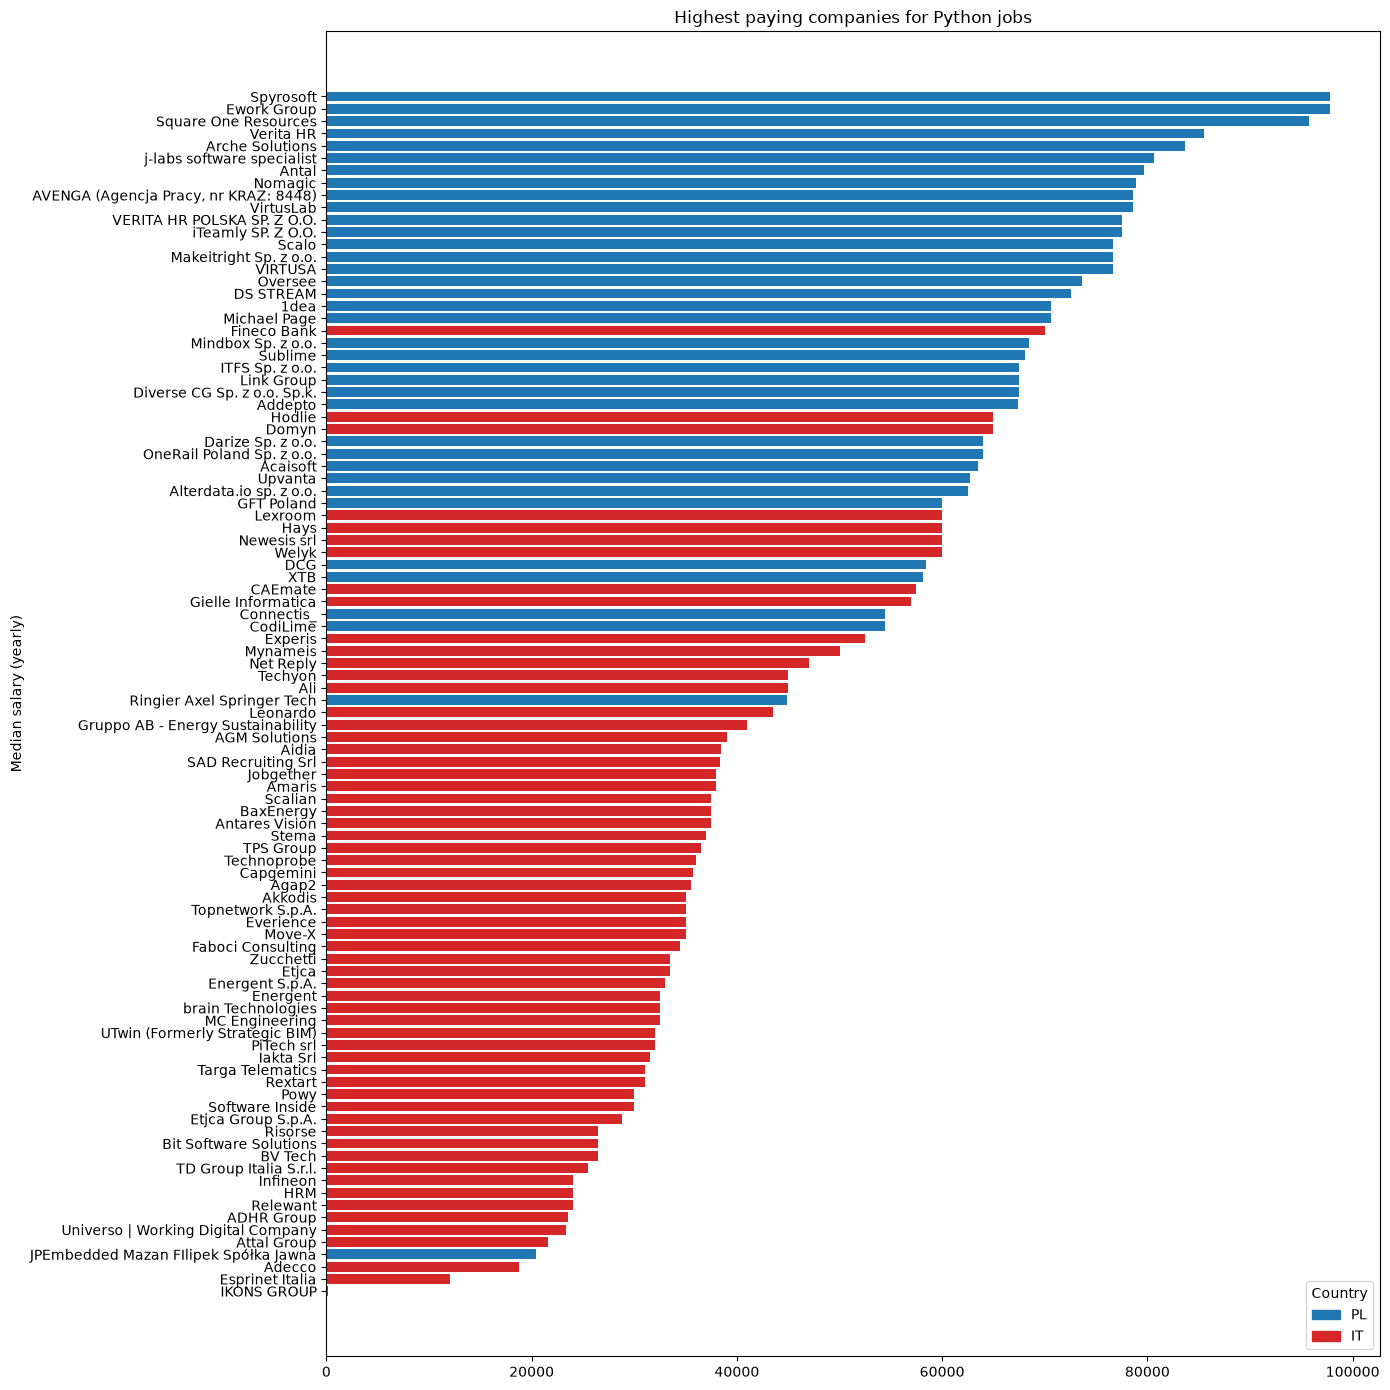

In [223]:
import matplotlib.pyplot as plt

# Top paying companies for Python jobs (combined), with country and best url
nf_top = nf_py[["name", "median_salary", "url"]].copy()
nf_top["company"] = nf_top["name"]
nf_top["country"] = "PL"
nf_top["source"] = "NoFluffJobs"
tc_top = tc_py[["company", "median_salary", "url"]].copy()
tc_top["country"] = "IT"
tc_top["source"] = "TechCompenso"
cj_top = cj_py[["company", "median_salary", "link"]].copy()
cj_top["country"] = "IT"
cj_top = cj_top.rename(columns={"link": "url"})
cj_top["source"] = "Careerjet"
all_py = pd.concat([nf_top[["company", "median_salary", "country", "url", "source"]],
                    tc_top[["company", "median_salary", "country", "url", "source"]],
                    cj_top[["company", "median_salary", "country", "url", "source"]]], ignore_index=True)

# for each company keep the highest paying posting's url
all_py["median_salary"] = pd.to_numeric(all_py["median_salary"], errors="coerce")
all_py = all_py.dropna(subset=["company", "median_salary"])
all_py = all_py[all_py["company"].astype(str).str.strip() != ""]
if all_py.empty:
    result = pd.DataFrame(columns=["company", "median_salary", "country", "url", "source"])
else:
    best_idx = all_py.groupby("company")["median_salary"].idxmax()
    result = all_py.loc[best_idx, ["company", "median_salary", "country", "url", "source"]].sort_values("median_salary", ascending=False)
print("records:", len(result))

# save to csv
result.to_csv("python_top_companies.csv", index=False)
print("saved python_top_companies.csv")

colors = {"PL": "#1f77b4", "IT": "#d62728"}
bar_colors = [colors.get(c, "gray") for c in result["country"]]

plt.figure(figsize=(14, 14))
plt.barh(result["company"], result["median_salary"], color=bar_colors)
plt.title("Highest paying companies for Python jobs")
plt.ylabel("Median salary (yearly)")
plt.yticks()
from matplotlib.patches import Patch
handles = [Patch(color=colors[k], label=k) for k in colors]
plt.legend(handles=handles, title="Country")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


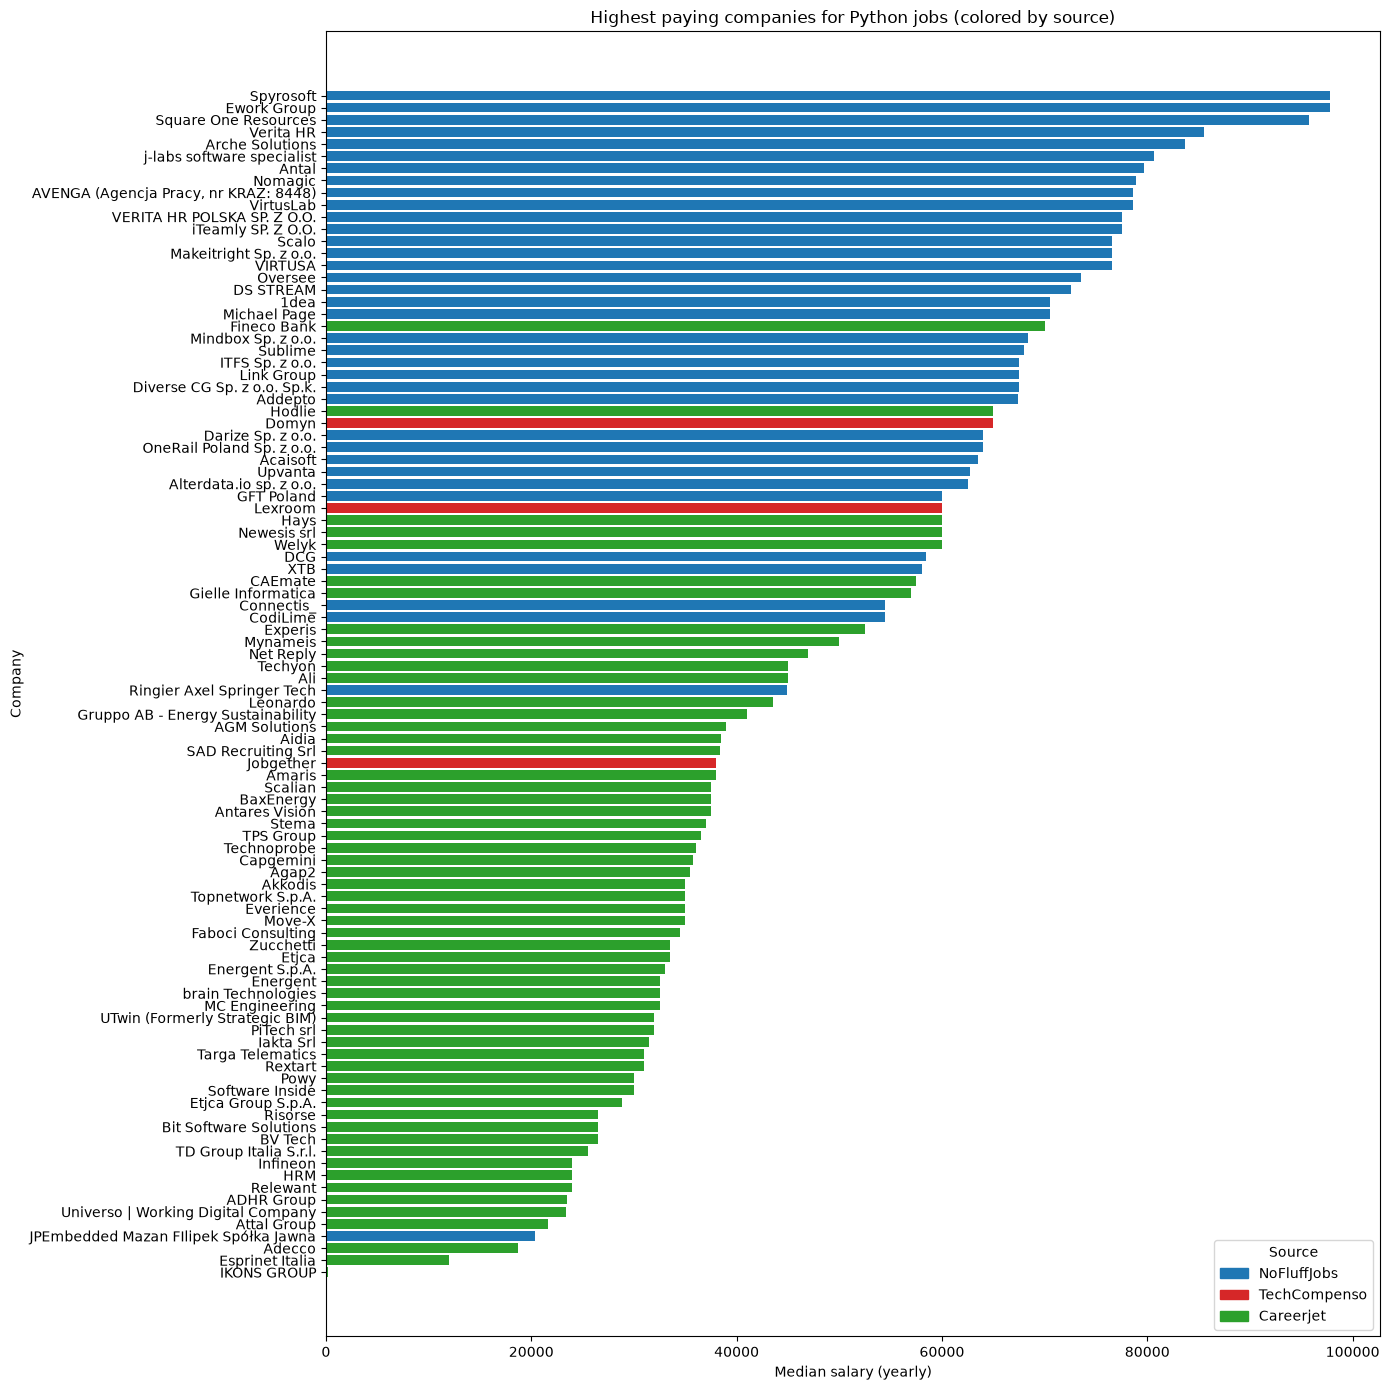

In [224]:
# Chart colored by source website
source_colors = {"NoFluffJobs": "#1f77b4", "TechCompenso": "#d62728", "Careerjet": "#2ca02c"}
source_bar_colors = [source_colors.get(s, "gray") for s in result["source"]]

plt.figure(figsize=(14, 14))
plt.barh(result["company"], result["median_salary"], color=source_bar_colors)
plt.title("Highest paying companies for Python jobs (colored by source)")
plt.xlabel("Median salary (yearly)")
plt.ylabel("Company")
plt.yticks()
from matplotlib.patches import Patch
source_handles = [Patch(color=source_colors[k], label=k) for k in source_colors]
plt.legend(handles=source_handles, title="Source")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [225]:
conn.close()

In [226]:
result


,company,median_salary,country,url,source
57,Spyrosoft,97776.0,PL,openstack-cloud-engineer-spyrosoft-remote,NoFluffJobs
41,Ework Group,97776.0,PL,python-backend-engineer-ework-group-warsaw,NoFluffJobs
32,Square One Resources,95760.0,PL,senior-data-scientist-square-one-resources-rem...,NoFluffJobs
46,Verita HR,85554.0,PL,senior-aws-python-developer-verita-hr-krakow,NoFluffJobs
7,Arche Solutions,83664.0,PL,senior-mlops-engineer-m-f-arche-solutions-remote,NoFluffJobs
...,...,...,...,...,...
171,Attal Group,21600.0,IT,https://www.careerjet.it/jobad/itcc88f96e86c0c...,Careerjet
9,JPEmbedded Mazan FIlipek Spółka Jawna,20406.0,PL,tester-systemowy-staz-praca-jpembedded-mazan-f...,NoFluffJobs
173,Adecco,18729.0,IT,https://www.careerjet.it/jobad/it93c0a298d482a...,Careerjet
119,Esprinet Italia,12000.0,IT,https://www.careerjet.it/jobad/it2425523dc160a...,Careerjet
